<a href="https://colab.research.google.com/github/munnamia1945/AI_ML_DL_CYS_Projects/blob/main/13-cross-dataset-ids-evaluation/cross-dataset-ids-evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Cell - 1 Primary Information
## Project 13: Cross-Dataset Intrusion Detection Evaluation

### Feature Compatibility, Label Mapping, and Generalization Between CICIDS2017 and UNSW-NB15

#### Research Objectives
1. Evaluate intrusion detection models independently on CICIDS2017 and UNSW-NB15.
2. Audit feature compatibility between the two datasets.
3. Develop a defensible common feature representation.
4. Evaluate cross-dataset generalization in both directions.
5. Analyze domain shift, class imbalance, and model limitations.

#### Experimental Design
- EXP-01: Train and test on CICIDS2017.
- EXP-02: Train and test on UNSW-NB15.
- EXP-03: Train on CICIDS2017 and test on UNSW-NB15.
- EXP-04: Train on UNSW-NB15 and test on CICIDS2017.

#### Important Methodological Rule
All preprocessing steps must be fitted using training data only.
Target-domain test data must never be used to fit preprocessing or models.

### Cell - 2 Libraries install and Drive mount

In [ ]:
!pip -q install xgboost lightgbm catboost joblib

### Cell 3 - Import libraries and mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os
import re
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import joblib

RANDOM_STATE = 42

print("Libraries imported successfully.")

Mounted at /content/drive
Libraries imported successfully.


### Cell - 4 Define dataset paths

In [ ]:
CICIDS_DIR = Path('/content/drive/MyDrive/Colab Notebooks/Projects House/project-13/Network_Intrusion/CICIDS2017')

UNSW_DIR = Path(
    '/content/drive/MyDrive/Colab Notebooks/Projects House/project-13/Network_Intrusion/UNSW-NB15'
)

OUTPUT_DIR = Path(
    '/content/drive/MyDrive/Colab Notebooks/Projects House/project-13/Output-4'
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

UNSW_TRAIN = UNSW_DIR / 'UNSW_NB15_training-set.csv'
UNSW_TEST = UNSW_DIR / 'UNSW_NB15_testing-set.csv'

print("CICIDS2017 folder:", CICIDS_DIR.exists())
print("UNSW-NB15 folder:", UNSW_DIR.exists())
print("UNSW training file:", UNSW_TRAIN.exists())
print("UNSW testing file:", UNSW_TEST.exists())
print("Output directory:", OUTPUT_DIR)

CICIDS2017 folder: True
UNSW-NB15 folder: True
UNSW training file: True
UNSW testing file: True
Output directory: /content/drive/MyDrive/Colab Notebooks/Projects House/project-13/Output-4


### Cell - 5 Verify dataset file

In [ ]:
print("UNSW-NB15 files:")

for file in sorted(UNSW_DIR.glob("*")):
    print(file.name)

print("\nCICIDS2017 CSV files:")

for file in sorted(CICIDS_DIR.glob("*.csv")):
    print(file.name)

UNSW-NB15 files:
UNSW_NB15_testing-set.csv
UNSW_NB15_training-set.csv

CICIDS2017 CSV files:
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv


### Cell - 6 Load UNSW-NB15

In [ ]:
unsw_train = pd.read_csv(UNSW_TRAIN, low_memory=False)
unsw_test = pd.read_csv(UNSW_TEST, low_memory=False)

print("UNSW Training shape:", unsw_train.shape)
print("UNSW Testing shape:", unsw_test.shape)

print("\nTraining columns:")
print(unsw_train.columns.tolist())

print("\nTesting columns:")
print(unsw_test.columns.tolist())

display(unsw_train.head())

UNSW Training shape: (175341, 45)
UNSW Testing shape: (82332, 45)

Training columns:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

Testing columns:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', '

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


### Cell - 7 Inspect UNSW labels

In [ ]:
print("Training binary label distribution:")
display(unsw_train['label'].value_counts(dropna=False))

print("\nTraining attack category distribution:")
display(unsw_train['attack_cat'].value_counts(dropna=False))

print("\nTesting binary label distribution:")
display(unsw_test['label'].value_counts(dropna=False))

print("\nTesting attack category distribution:")
display(unsw_test['attack_cat'].value_counts(dropna=False))

Training binary label distribution:


,count
label,
1,119341
0,56000



Training attack category distribution:


,count
attack_cat,
Normal,56000
Generic,40000
Exploits,33393
Fuzzers,18184
DoS,12264
Reconnaissance,10491
Analysis,2000
Backdoor,1746
Shellcode,1133



Testing binary label distribution:


,count
label,
1,45332
0,37000



Testing attack category distribution:


,count
attack_cat,
Normal,37000
Generic,18871
Exploits,11132
Fuzzers,6062
DoS,4089
Reconnaissance,3496
Analysis,677
Backdoor,583
Shellcode,378


### Cell 8 - Load and audit CICIDS2017 CSV files

In [ ]:
cic_files = sorted(CICIDS_DIR.glob("*.csv"))

if not cic_files:
    raise FileNotFoundError(
        "No CICIDS2017 CSV files found. Check CICIDS_DIR."
    )

print("Number of CICIDS2017 CSV files:", len(cic_files))

for file in cic_files:
    print(file.name)

cic_sample = pd.read_csv(cic_files[0], nrows=5, low_memory=False)

print("\nCICIDS2017 sample columns:")
print(cic_sample.columns.tolist())

display(cic_sample.head())

Number of CICIDS2017 CSV files: 8
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv

CICIDS2017 sample columns:
[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6,0,...,20,0,0,0,0,0,0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6,0,...,20,0,0,0,0,0,0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6,0,...,20,0,0,0,0,0,0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6,0,...,20,0,0,0,0,0,0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6,0,...,20,0,0,0,0,0,0,0,0,BENIGN


### Cell 9 - Load CICIDS2017

In [ ]:
cic_frames = []

for file in cic_files:
    print("Loading:", file.name)

    temp = pd.read_csv(file, low_memory=False)

    temp.columns = (
        temp.columns.astype(str)
        .str.strip()
    )

    temp['_source_file'] = file.name

    cic_frames.append(temp)

cic_df = pd.concat(
    cic_frames,
    ignore_index=True
)

print("\nCombined CICIDS2017 shape:", cic_df.shape)
display(cic_df.head())

Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Wednesday-workingHours.pcap_ISCX.csv

Combined CICIDS2017 shape: (2830743, 80)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,_source_file
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


### Cell 10 - Clean column names and inspect labels

In [ ]:
cic_df.columns = (
    cic_df.columns.astype(str)
    .str.strip()
)

unsw_train.columns = (
    unsw_train.columns.astype(str)
    .str.strip()
)

unsw_test.columns = (
    unsw_test.columns.astype(str)
    .str.strip()
)

print("CICIDS2017 columns:")
print(cic_df.columns.tolist())

print("\nCICIDS2017 label distribution:")
display(cic_df['Label'].value_counts(dropna=False))

print("\nUNSW training labels:")
display(unsw_train['label'].value_counts(dropna=False))

CICIDS2017 columns:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Cou

,count
Label,
BENIGN,2273097
DoS Hulk,231073
PortScan,158930
DDoS,128027
DoS GoldenEye,10293
FTP-Patator,7938
SSH-Patator,5897
DoS slowloris,5796
DoS Slowhttptest,5499



UNSW training labels:


,count
label,
1,119341
0,56000


### Cell 11 - Normalize label text

In [ ]:
cic_df['Label'] = (
    cic_df['Label']
    .astype(str)
    .str.strip()
)

for df in [unsw_train, unsw_test]:
    df['attack_cat'] = (
        df['attack_cat']
        .astype('string')
        .str.strip()
    )

print("CICIDS labels:")
print(sorted(cic_df['Label'].unique()))

print("\nUNSW attack categories:")
print(
    sorted(
        unsw_train['attack_cat']
        .dropna()
        .unique()
        .tolist()
    )
)

CICIDS labels:
['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack � Brute Force', 'Web Attack � Sql Injection', 'Web Attack � XSS']

UNSW attack categories:
['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']


### Cell 12 - Dataset structure audit

In [ ]:
print("CICIDS2017")
print("Rows:", len(cic_df))
print("Columns:", len(cic_df.columns))
print("Duplicate rows:", cic_df.duplicated().sum())

print("\nUNSW-NB15 Training")
print("Rows:", len(unsw_train))
print("Columns:", len(unsw_train.columns))
print("Duplicate rows:", unsw_train.duplicated().sum())

print("\nUNSW-NB15 Testing")
print("Rows:", len(unsw_test))
print("Columns:", len(unsw_test.columns))
print("Duplicate rows:", unsw_test.duplicated().sum())

print("\nMissing values in UNSW training:")
display(
    unsw_train.isnull().sum()
    .sort_values(ascending=False)
    .head(20)
)

print("\nMissing values in CICIDS2017:")
display(
    cic_df.isnull().sum()
    .sort_values(ascending=False)
    .head(20)
)

CICIDS2017
Rows: 2830743
Columns: 80
Duplicate rows: 256479

UNSW-NB15 Training
Rows: 175341
Columns: 45
Duplicate rows: 0

UNSW-NB15 Testing
Rows: 82332
Columns: 45
Duplicate rows: 0

Missing values in UNSW training:


,0
id,0
dur,0
proto,0
service,0
state,0
spkts,0
dpkts,0
sbytes,0
dbytes,0
rate,0



Missing values in CICIDS2017:


,0
Flow Bytes/s,1358
Destination Port,0
Total Fwd Packets,0
Flow Duration,0
Total Length of Fwd Packets,0
Total Length of Bwd Packets,0
Fwd Packet Length Max,0
Total Backward Packets,0
Fwd Packet Length Min,0
Fwd Packet Length Mean,0


### Cell 13 - Create binary labels

In [ ]:
cic_df['binary_label'] = (
    cic_df['Label']
    .str.upper()
    .str.strip()
    .ne('BENIGN')
    .astype(int)
)

unsw_train['binary_label'] = pd.to_numeric(
    unsw_train['label'],
    errors='coerce'
)

unsw_test['binary_label'] = pd.to_numeric(
    unsw_test['label'],
    errors='coerce'
)

print("CICIDS binary labels:")
display(cic_df['binary_label'].value_counts())

print("\nUNSW training binary labels:")
display(unsw_train['binary_label'].value_counts(dropna=False))

print("\nUNSW testing binary labels:")
display(unsw_test['binary_label'].value_counts(dropna=False))

CICIDS binary labels:


,count
binary_label,
0,2273097
1,557646



UNSW training binary labels:


,count
binary_label,
1,119341
0,56000



UNSW testing binary labels:


,count
binary_label,
1,45332
0,37000


### Cell 14 - Verify binary label consistency

In [ ]:
for name, df in [
    ("UNSW Training", unsw_train),
    ("UNSW Testing", unsw_test)
]:
    mismatch = (
        df['attack_cat'].isna()
        & df['binary_label'].eq(1)
    )

    print(name)
    print("Missing attack category but attack label:", mismatch.sum())

    print(
        pd.crosstab(
            df['binary_label'],
            df['attack_cat'].fillna('MISSING')
        )
    )

UNSW Training
Missing attack category but attack label: 0
attack_cat    Analysis  Backdoor    DoS  Exploits  Fuzzers  Generic  Normal  \
binary_label                                                                  
0                    0         0      0         0        0        0   56000   
1                 2000      1746  12264     33393    18184    40000       0   

attack_cat    Reconnaissance  Shellcode  Worms  
binary_label                                    
0                          0          0      0  
1                      10491       1133    130  
UNSW Testing
Missing attack category but attack label: 0
attack_cat    Analysis  Backdoor   DoS  Exploits  Fuzzers  Generic  Normal  \
binary_label                                                                 
0                    0         0     0         0        0        0   37000   
1                  677       583  4089     11132     6062    18871       0   

attack_cat    Reconnaissance  Shellcode  Worms  
binary_lab

### Cell 15 - Save dataset audit

In [ ]:
audit = {
    "CICIDS2017_rows": int(len(cic_df)),
    "CICIDS2017_columns": int(len(cic_df.columns)),
    "CICIDS2017_csv_files": [f.name for f in cic_files],
    "UNSW_training_rows": int(len(unsw_train)),
    "UNSW_testing_rows": int(len(unsw_test)),
    "UNSW_training_columns": int(len(unsw_train.columns)),
    "UNSW_testing_columns": int(len(unsw_test.columns)),
    "CICIDS_binary_distribution": {
        str(k): int(v)
        for k, v in cic_df['binary_label'].value_counts().items()
    },
    "UNSW_binary_distribution": {
        str(k): int(v)
        for k, v in unsw_train['binary_label'].value_counts().items()
    }
}

with open(OUTPUT_DIR / "dataset_audit.json", "w") as f:
    json.dump(audit, f, indent=4)

print("Dataset audit saved.")

Dataset audit saved.


### Cell 16 - Inspect possible common features

In [ ]:
cic_columns = set(cic_df.columns)
unsw_columns = set(unsw_train.columns)

print("Exact common column names:")
print(sorted(cic_columns.intersection(unsw_columns)))

candidate_mapping = {
    "Flow Duration": "dur",
    "Total Fwd Packets": "spkts",
    "Total Backward Packets": "dpkts",
    "Total Length of Fwd Packets": "sbytes",
    "Total Length of Bwd Packets": "dbytes",
    "Source Port": "sport",
    "Destination Port": "dsport",
    "Protocol": "proto"
}

print("\nCandidate feature mapping (not yet validated):")

for cic_col, unsw_col in candidate_mapping.items():
    print(
        cic_col,
        "<->",
        unsw_col,
        "| CIC exists:", cic_col in cic_columns,
        "| UNSW exists:", unsw_col in unsw_columns
    )

Exact common column names:
['binary_label']

Candidate feature mapping (not yet validated):
Flow Duration <-> dur | CIC exists: True | UNSW exists: True
Total Fwd Packets <-> spkts | CIC exists: True | UNSW exists: True
Total Backward Packets <-> dpkts | CIC exists: True | UNSW exists: True
Total Length of Fwd Packets <-> sbytes | CIC exists: True | UNSW exists: True
Total Length of Bwd Packets <-> dbytes | CIC exists: True | UNSW exists: True
Source Port <-> sport | CIC exists: False | UNSW exists: False
Destination Port <-> dsport | CIC exists: True | UNSW exists: False
Protocol <-> proto | CIC exists: False | UNSW exists: True


### Cell 17 — Feature compatibility review

## Feature Compatibility Review

Candidate features must be checked for:
- Semantic meaning
- Measurement units
- Source/destination direction
- Flow construction methodology
- Missing-value behavior
- Dataset-specific collection characteristics

Similar column names do not establish feature equivalence.

Features with uncertain definitions will not be included in the
cross-dataset experiment until their compatibility is verified.

### Cell 18 - Create feature mapping only after validation

In [ ]:
# Candidate mapping for manual verification.
# Do not treat these pairs as equivalent without checking dataset documentation.

validated_mapping = {
    "Flow Duration": "dur",
    "Total Fwd Packets": "spkts",
    "Total Backward Packets": "dpkts",
    "Total Length of Fwd Packets": "sbytes",
    "Total Length of Bwd Packets": "dbytes"
}

mapping_audit = []

for cic_col, unsw_col in validated_mapping.items():
    mapping_audit.append({
        "CICIDS2017_feature": cic_col,
        "UNSW_NB15_feature": unsw_col,
        "CIC_exists": cic_col in cic_df.columns,
        "UNSW_exists": unsw_col in unsw_train.columns,
        "status": "Candidate - requires semantic verification"
    })

mapping_df = pd.DataFrame(mapping_audit)

display(mapping_df)

mapping_df.to_csv(
    OUTPUT_DIR / "feature_mapping_audit.csv",
    index=False
)

,CICIDS2017_feature,UNSW_NB15_feature,CIC_exists,UNSW_exists,status
0,Flow Duration,dur,True,True,Candidate - requires semantic verification
1,Total Fwd Packets,spkts,True,True,Candidate - requires semantic verification
2,Total Backward Packets,dpkts,True,True,Candidate - requires semantic verification
3,Total Length of Fwd Packets,sbytes,True,True,Candidate - requires semantic verification
4,Total Length of Bwd Packets,dbytes,True,True,Candidate - requires semantic verification


### Cell 19 - Normalize column names and verify schema

In [ ]:
# Normalize column names to avoid whitespace and punctuation issues.

def normalize_column_name(name):
    name = str(name).strip().lower()
    name = re.sub(r'[^a-z0-9]+', '', name)
    return name

cic_column_lookup = {
    normalize_column_name(col): col
    for col in cic_df.columns
}

unsw_column_lookup = {
    normalize_column_name(col): col
    for col in unsw_train.columns
}

print("CICIDS2017 relevant columns:")

for key, col in cic_column_lookup.items():
    if any(term in key for term in [
        "flowduration",
        "totalfwdpackets",
        "totalbackwardpackets",
        "totallengthoffwdpackets",
        "totallengthofbwdpackets",
        "label"
    ]):
        print(repr(col))

print("\nUNSW-NB15 relevant columns:")

for key, col in unsw_column_lookup.items():
    if key in ["dur", "spkts", "dpkts", "sbytes", "dbytes", "label"]:
        print(repr(col))

CICIDS2017 relevant columns:
'Flow Duration'
'Total Fwd Packets'
'Total Backward Packets'
'Total Length of Fwd Packets'
'Total Length of Bwd Packets'
'Label'
'binary_label'

UNSW-NB15 relevant columns:
'dur'
'spkts'
'dpkts'
'sbytes'
'dbytes'
'label'


### Cell 20 - Validate feature mapping

In [ ]:
feature_pairs = {
    "duration": ("Flow Duration", "dur"),
    "forward_packets": ("Total Fwd Packets", "spkts"),
    "backward_packets": ("Total Backward Packets", "dpkts"),
    "forward_bytes": ("Total Length of Fwd Packets", "sbytes"),
    "backward_bytes": ("Total Length of Bwd Packets", "dbytes")
}

resolved_mapping = {}

for feature, (cic_name, unsw_name) in feature_pairs.items():

    cic_key = normalize_column_name(cic_name)
    unsw_key = normalize_column_name(unsw_name)

    cic_actual = cic_column_lookup.get(cic_key)
    unsw_actual = unsw_column_lookup.get(unsw_key)

    resolved_mapping[feature] = {
        "CICIDS2017": cic_actual,
        "UNSW_NB15": unsw_actual
    }

    print(
        feature,
        "| CIC:", cic_actual,
        "| UNSW:", unsw_actual,
        "| Valid:", cic_actual is not None and unsw_actual is not None
    )

if not all(
    item["CICIDS2017"] is not None
    and item["UNSW_NB15"] is not None
    for item in resolved_mapping.values()
):
    raise ValueError("Feature mapping failed. Check Cell 19 output.")

duration | CIC: Flow Duration | UNSW: dur | Valid: True
forward_packets | CIC: Total Fwd Packets | UNSW: spkts | Valid: True
backward_packets | CIC: Total Backward Packets | UNSW: dpkts | Valid: True
forward_bytes | CIC: Total Length of Fwd Packets | UNSW: sbytes | Valid: True
backward_bytes | CIC: Total Length of Bwd Packets | UNSW: dbytes | Valid: True


### Cell 21 - Inspect feature data and duration ranges

In [ ]:
print("CICIDS2017 feature statistics:")

for feature, mapping in resolved_mapping.items():

    col = mapping["CICIDS2017"]

    values = pd.to_numeric(
        cic_df[col],
        errors="coerce"
    )

    print(f"\n{feature} ({col})")
    print(values.describe())

print("\nUNSW-NB15 feature statistics:")

for feature, mapping in resolved_mapping.items():

    col = mapping["UNSW_NB15"]

    values = pd.to_numeric(
        unsw_train[col],
        errors="coerce"
    )

    print(f"\n{feature} ({col})")
    print(values.describe())

CICIDS2017 feature statistics:

duration (Flow Duration)
count    2.830743e+06
mean     1.478566e+07
std      3.365374e+07
min     -1.300000e+01
25%      1.550000e+02
50%      3.131600e+04
75%      3.204828e+06
max      1.200000e+08
Name: Flow Duration, dtype: float64

forward_packets (Total Fwd Packets)
count    2.830743e+06
mean     9.361160e+00
std      7.496728e+02
min      1.000000e+00
25%      2.000000e+00
50%      2.000000e+00
75%      5.000000e+00
max      2.197590e+05
Name: Total Fwd Packets, dtype: float64

backward_packets (Total Backward Packets)
count    2.830743e+06
mean     1.039377e+01
std      9.973883e+02
min      0.000000e+00
25%      1.000000e+00
50%      2.000000e+00
75%      4.000000e+00
max      2.919220e+05
Name: Total Backward Packets, dtype: float64

forward_bytes (Total Length of Fwd Packets)
count    2.830743e+06
mean     5.493024e+02
std      9.993589e+03
min      0.000000e+00
25%      1.200000e+01
50%      6.200000e+01
75%      1.870000e+02
max      1.2900

### Cell 22 - Create a verified feature mapping report

In [ ]:
mapping_report = []

for feature, mapping in resolved_mapping.items():

    cic_col = mapping["CICIDS2017"]
    unsw_col = mapping["UNSW_NB15"]

    mapping_report.append({
        "Common_Feature": feature,
        "CICIDS2017_Column": cic_col,
        "UNSW_NB15_Column": unsw_col,
        "CICIDS_DataType": str(cic_df[cic_col].dtype),
        "UNSW_DataType": str(unsw_train[unsw_col].dtype),
        "Compatibility": "Candidate - semantic and unit review required"
    })

mapping_report_df = pd.DataFrame(mapping_report)

display(mapping_report_df)

mapping_report_df.to_csv(
    OUTPUT_DIR / "verified_feature_mapping.csv",
    index=False
)

print("Feature mapping report saved.")

,Common_Feature,CICIDS2017_Column,UNSW_NB15_Column,CICIDS_DataType,UNSW_DataType,Compatibility
0,duration,Flow Duration,dur,int64,float64,Candidate - semantic and unit review required
1,forward_packets,Total Fwd Packets,spkts,int64,int64,Candidate - semantic and unit review required
2,backward_packets,Total Backward Packets,dpkts,int64,int64,Candidate - semantic and unit review required
3,forward_bytes,Total Length of Fwd Packets,sbytes,int64,int64,Candidate - semantic and unit review required
4,backward_bytes,Total Length of Bwd Packets,dbytes,int64,int64,Candidate - semantic and unit review required


Feature mapping report saved.


### Cell 23 - Check duration conversion

In [ ]:
cic_duration_col = resolved_mapping["duration"]["CICIDS2017"]
unsw_duration_col = resolved_mapping["duration"]["UNSW_NB15"]

cic_duration = pd.to_numeric(
    cic_df[cic_duration_col],
    errors="coerce"
)

unsw_duration = pd.to_numeric(
    unsw_train[unsw_duration_col],
    errors="coerce"
)

print("CICIDS2017 duration (raw):")
print(cic_duration.describe())

print("\nCICIDS2017 duration converted to seconds:")
print((cic_duration / 1_000_000).describe())

print("\nUNSW-NB15 duration:")
print(unsw_duration.describe())

CICIDS2017 duration (raw):
count    2.830743e+06
mean     1.478566e+07
std      3.365374e+07
min     -1.300000e+01
25%      1.550000e+02
50%      3.131600e+04
75%      3.204828e+06
max      1.200000e+08
Name: Flow Duration, dtype: float64

CICIDS2017 duration converted to seconds:
count    2.830743e+06
mean     1.478566e+01
std      3.365374e+01
min     -1.300000e-05
25%      1.550000e-04
50%      3.131600e-02
75%      3.204829e+00
max      1.200000e+02
Name: Flow Duration, dtype: float64

UNSW-NB15 duration:
count    175341.000000
mean          1.359389
std           6.480249
min           0.000000
25%           0.000008
50%           0.001582
75%           0.668069
max          59.999989
Name: dur, dtype: float64


### Cell 24 - Define common feature columns

In [ ]:
COMMON_FEATURES = [
    "duration",
    "forward_packets",
    "backward_packets",
    "forward_bytes",
    "backward_bytes"
]

CIC_FEATURES = [
    resolved_mapping[f]["CICIDS2017"]
    for f in COMMON_FEATURES
]

UNSW_FEATURES = [
    resolved_mapping[f]["UNSW_NB15"]
    for f in COMMON_FEATURES
]

print("Common feature order:", COMMON_FEATURES)
print("CICIDS columns:", CIC_FEATURES)
print("UNSW columns:", UNSW_FEATURES)

Common feature order: ['duration', 'forward_packets', 'backward_packets', 'forward_bytes', 'backward_bytes']
CICIDS columns: ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets']
UNSW columns: ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes']


### Cell 25 - Prepare CICIDS2017 feature dataset

In [ ]:
# Cell 25 - Prepare CICIDS2017 feature dataset (deduplicate before splitting)

# Remove exact duplicate source records before creating the train-test split.
# Exclude only the source filename: the same record may occur in multiple CSV files.
dedup_columns = [
    col for col in cic_df.columns
    if col != "_source_file"
]

original_rows = len(cic_df)
duplicate_rows = int(cic_df.duplicated(subset=dedup_columns).sum())

print("Original CICIDS2017 rows:", original_rows)
print("Exact duplicate rows found:", duplicate_rows)

cic_clean_source = (
    cic_df
    .drop_duplicates(subset=dedup_columns, keep="first")
    .copy()
    .reset_index(drop=True)
)

print("Rows after exact duplicate removal:", len(cic_clean_source))
print("Rows removed:", original_rows - len(cic_clean_source))

# Build the common-feature dataset from the deduplicated source records.
cic_data = pd.DataFrame(index=cic_clean_source.index)

for common_name in COMMON_FEATURES:
    source_col = resolved_mapping[common_name]["CICIDS2017"]
    cic_data[common_name] = pd.to_numeric(
        cic_clean_source[source_col],
        errors="coerce"
    )

# CICIDS2017 Flow Duration is recorded in microseconds; convert to seconds.
cic_data["duration"] = cic_data["duration"] / 1_000_000

cic_data["label"] = pd.to_numeric(
    cic_clean_source["binary_label"],
    errors="coerce"
)

# Preserve the original multiclass attack category for sampling diagnostics.
# This column is not included in the five model input features.
cic_data["attack_category"] = (
    cic_clean_source["Label"].astype(str).str.strip()
)

print("\nBefore invalid-value cleaning:", cic_data.shape)

# Replace infinite values and remove invalid labels.
cic_data = cic_data.replace([np.inf, -np.inf], np.nan)
cic_data = cic_data.dropna(subset=["label"])
cic_data = cic_data[cic_data["label"].isin([0, 1])].copy()

# Negative packet counts, byte counts, or durations are invalid for these features.
negative_mask = cic_data[COMMON_FEATURES].lt(0).any(axis=1)
print("Rows with negative feature values:", int(negative_mask.sum()))
cic_data = cic_data.loc[~negative_mask].copy()

cic_data["label"] = cic_data["label"].astype(int)
cic_data = cic_data.reset_index(drop=True)

print("\nFinal CICIDS2017 prepared shape:", cic_data.shape)
print("\nFinal binary label distribution:")
display(cic_data["label"].value_counts().sort_index())

# Audit repeated model-input signatures after feature reduction.
# These are not necessarily duplicate raw records: distinct source flows can
# collapse to the same five selected feature values.
cic_data["_feature_group"] = pd.util.hash_pandas_object(
    cic_data[COMMON_FEATURES],
    index=False
).astype("uint64")

group_sizes = cic_data.groupby("_feature_group").size()
label_counts_per_group = cic_data.groupby("_feature_group")["label"].nunique()

repeated_rows = int(group_sizes[group_sizes > 1].sum())
repeated_groups = int((group_sizes > 1).sum())
conflicting_groups = int((label_counts_per_group > 1).sum())

print("\\nFive-feature signature audit:")
print("Unique feature signatures:", int(group_sizes.size))
print("Rows belonging to repeated signatures:", repeated_rows)
print("Repeated feature-signature groups:", repeated_groups)
print("Feature signatures associated with BOTH labels:", conflicting_groups)

# Keep the grouping key only for splitting; it is not a model input.
print("\\nPrepared CICIDS2017 shape:", cic_data.shape)


Original CICIDS2017 rows: 2830743
Exact duplicate rows found: 308381
Rows after exact duplicate removal: 2522362
Rows removed: 308381

Before invalid-value cleaning: (2522362, 7)
Rows with negative feature values: 107

Final CICIDS2017 prepared shape: (2522255, 7)

Final binary label distribution:


,count
label,
0,2096377
1,425878


\nFive-feature signature audit:
Unique feature signatures: 1785638
Rows belonging to repeated signatures: 827226
Repeated feature-signature groups: 90609
Feature signatures associated with BOTH labels: 1878
\nPrepared CICIDS2017 shape: (2522255, 8)


### Cell 26 - Prepare UNSW-NB15 feature datasets

In [ ]:
def prepare_unsw(df):

    data = pd.DataFrame()

    for common_name in COMMON_FEATURES:
        source_col = resolved_mapping[common_name]["UNSW_NB15"]

        data[common_name] = pd.to_numeric(
            df[source_col],
            errors="coerce"
        )

    data["label"] = pd.to_numeric(
        df["binary_label"],
        errors="coerce"
    )

    data = data.replace([np.inf, -np.inf], np.nan)

    data = data.dropna(subset=["label"])

    data = data[data["label"].isin([0, 1])]

    invalid_mask = (
        data[COMMON_FEATURES].lt(0).any(axis=1)
    )

    print("Invalid negative rows removed:", invalid_mask.sum())

    data = data.loc[~invalid_mask].copy()

    data["label"] = data["label"].astype(int)

    return data


unsw_train_data = prepare_unsw(unsw_train)
unsw_test_data = prepare_unsw(unsw_test)

print("UNSW training shape:", unsw_train_data.shape)
print("UNSW testing shape:", unsw_test_data.shape)

print("\nTraining distribution:")
display(unsw_train_data["label"].value_counts())

print("\nTesting distribution:")
display(unsw_test_data["label"].value_counts())

Invalid negative rows removed: 0
Invalid negative rows removed: 0
UNSW training shape: (175341, 6)
UNSW testing shape: (82332, 6)

Training distribution:


,count
label,
1,119341
0,56000



Testing distribution:


,count
label,
1,45332
0,37000


### Cell 27 - Check cleaned datasets

In [ ]:
print("CICIDS2017:")
display(cic_data[COMMON_FEATURES].describe())

print("\nUNSW-NB15 training:")
display(unsw_train_data[COMMON_FEATURES].describe())

print("\nMissing values:")

print(
    "CICIDS:",
    cic_data[COMMON_FEATURES].isnull().sum().sum()
)

print(
    "UNSW train:",
    unsw_train_data[COMMON_FEATURES].isnull().sum().sum()
)

print(
    "UNSW test:",
    unsw_test_data[COMMON_FEATURES].isnull().sum().sum()
)

CICIDS2017:


,duration,forward_packets,backward_packets,forward_bytes,backward_bytes
count,2.522255e+06,2.522255e+06,2.522255e+06,2.522255e+06,2.522255e+06
mean,1.658203e+01,1.027666e+01,1.156641e+01,6.116009e+02,1.813392e+04
std,3.522484e+01,7.941906e+02,1.056617e+03,1.058522e+04,2.397485e+06
min,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.080000e-04,2.000000e+00,1.000000e+00,1.200000e+01,6.000000e+00
50%,5.058000e-02,2.000000e+00,2.000000e+00,6.600000e+01,1.550000e+02
75%,5.329953e+00,6.000000e+00,5.000000e+00,3.320000e+02,9.890000e+02
max,1.200000e+02,2.197590e+05,2.919220e+05,1.290000e+07,6.554530e+08



UNSW-NB15 training:


,duration,forward_packets,backward_packets,forward_bytes,backward_bytes
count,175341.000000,175341.000000,175341.000000,1.753410e+05,1.753410e+05
mean,1.359389,20.298664,18.969591,8.844844e+03,1.492892e+04
std,6.480249,136.887597,110.258271,1.747656e+05,1.436542e+05
min,0.000000,1.000000,0.000000,2.800000e+01,0.000000e+00
25%,0.000008,2.000000,0.000000,1.140000e+02,0.000000e+00
50%,0.001582,2.000000,2.000000,4.300000e+02,1.640000e+02
75%,0.668069,12.000000,10.000000,1.418000e+03,1.102000e+03
max,59.999989,9616.000000,10974.000000,1.296523e+07,1.465555e+07



Missing values:
CICIDS: 0
UNSW train: 0
UNSW test: 0


### Cell 28 - Create experimental splits

In [ ]:
# Group-aware CICIDS2017 split to prevent identical five-feature inputs
# from appearing in both training and testing partitions.

from sklearn.model_selection import GroupShuffleSplit

# First create a stratified 250,000-row working sample to keep the experiment
# computationally manageable. The subsequent split keeps each feature group
# entirely in either train or test.
cic_working_sample, _ = train_test_split(
    cic_data,
    train_size=250_000,
    stratify=cic_data["label"],
    random_state=RANDOM_STATE
)

# Use the exact five model-input features to define groups.
# Identical model inputs are assigned to the same group, even if their labels
# conflict; conflicting labels are separately reported in the audit above.
cic_groups = pd.util.hash_pandas_object(
    cic_working_sample[COMMON_FEATURES],
    index=False
).astype("uint64")

group_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

train_idx, test_idx = next(
    group_splitter.split(
        cic_working_sample,
        cic_working_sample["label"],
        groups=cic_groups
    )
)

cic_train = (
    cic_working_sample.iloc[train_idx]
    .drop(columns=["_feature_group"], errors="ignore")
    .reset_index(drop=True)
)

cic_test = (
    cic_working_sample.iloc[test_idx]
    .drop(columns=["_feature_group"], errors="ignore")
    .reset_index(drop=True)
)

# Verify there is no overlap in five-feature signatures across the split.
train_signatures = set(
    pd.util.hash_pandas_object(
        cic_train[COMMON_FEATURES],
        index=False
    ).astype("uint64")
)

test_signatures = set(
    pd.util.hash_pandas_object(
        cic_test[COMMON_FEATURES],
        index=False
    ).astype("uint64")
)

signature_overlap = len(train_signatures.intersection(test_signatures))

unsw_train_exp = unsw_train_data.copy()
unsw_test_exp = unsw_test_data.copy()

print("CICIDS working sample:", cic_working_sample.shape)
print("CICIDS train:", cic_train.shape)
print("CICIDS test:", cic_test.shape)
print("UNSW train:", unsw_train_exp.shape)
print("UNSW test:", unsw_test_exp.shape)

print("\\nIdentical five-feature signatures across CICIDS train/test:", signature_overlap)

print("\\nCICIDS training labels:")
display(cic_train["label"].value_counts().sort_index())

print("\\nCICIDS testing labels:")
display(cic_test["label"].value_counts().sort_index())

if signature_overlap != 0:
    raise RuntimeError(
        "Leakage audit failed: identical five-feature signatures occur "
        "in both CICIDS train and test partitions."
    )

print("\\nGroup-aware split completed: no five-feature signature overlap.")


CICIDS working sample: (250000, 8)
CICIDS train: (200908, 7)
CICIDS test: (49092, 7)
UNSW train: (175341, 6)
UNSW test: (82332, 6)
\nIdentical five-feature signatures across CICIDS train/test: 0
\nCICIDS training labels:


,count
label,
0,167121
1,33787


\nCICIDS testing labels:


,count
label,
0,40667
1,8425


\nGroup-aware split completed: no five-feature signature overlap.


### Cell 29 - Save prepared datasets

In [ ]:
cic_train.to_csv(
    OUTPUT_DIR / "cicids_train_prepared.csv",
    index=False
)

cic_test.to_csv(
    OUTPUT_DIR / "cicids_test_prepared.csv",
    index=False
)

unsw_train_exp.to_csv(
    OUTPUT_DIR / "unsw_train_prepared.csv",
    index=False
)

unsw_test_exp.to_csv(
    OUTPUT_DIR / "unsw_test_prepared.csv",
    index=False
)

print("All prepared datasets saved successfully.")

All prepared datasets saved successfully.


### Cell 30 - Import model evaluation utilities

In [ ]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline

print("Evaluation utilities ready.")

Evaluation utilities ready.


### Cell 31 — Define four ML models

In [ ]:
def create_models(y_train):

    negative_count = int((y_train == 0).sum())
    positive_count = int((y_train == 1).sum())

    scale_pos_weight = (
        negative_count / positive_count
        if positive_count > 0 else 1.0
    )

    models = {

        "Random Forest": RandomForestClassifier(
            n_estimators=150,
            max_depth=None,
            min_samples_split=2,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),

        "XGBoost": XGBClassifier(
            n_estimators=150,
            max_depth=6,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=scale_pos_weight,
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),

        "LightGBM": LGBMClassifier(
            n_estimators=150,
            learning_rate=0.1,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1
        ),

        "CatBoost": CatBoostClassifier(
            iterations=150,
            depth=6,
            learning_rate=0.1,
            auto_class_weights="Balanced",
            random_seed=RANDOM_STATE,
            verbose=0,
            allow_writing_files=False,
            thread_count=-1
        )
    }

    return models


print("Model configuration ready.")

Model configuration ready.


### Cell 32 - Define preprocessing pipeline

In [ ]:
def create_pipeline(model):

    pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "log_transform",
            FunctionTransformer(
                np.log1p,
                feature_names_out="one-to-one"
            )
        ),
        (
            "classifier",
            model
        )
    ])

    return pipeline


print("Preprocessing pipeline ready.")

Preprocessing pipeline ready.


### Cell 33 - Define evaluation function

In [ ]:
def evaluate_experiment(
    experiment_name,
    X_train,
    y_train,
    X_test,
    y_test
):

    results = []
    fitted_models = {}

    models = create_models(y_train)

    X_train = X_train[COMMON_FEATURES].copy()
    X_test = X_test[COMMON_FEATURES].copy()

    for model_name, model in models.items():

        print("\n" + "=" * 60)
        print("Experiment:", experiment_name)
        print("Model:", model_name)
        print("=" * 60)

        pipeline = create_pipeline(model)

        start_train = time.time()

        pipeline.fit(X_train, y_train)

        train_time = time.time() - start_train

        start_inference = time.time()

        predictions = pipeline.predict(X_test)

        inference_time = time.time() - start_inference

        cm = confusion_matrix(
            y_test,
            predictions,
            labels=[0, 1]
        )

        tn, fp, fn, tp = cm.ravel()

        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

        accuracy = accuracy_score(y_test, predictions)

        precision = precision_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )

        recall = recall_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )

        macro_f1 = f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )

        report = classification_report(
            y_test,
            predictions,
            labels=[0, 1],
            target_names=["Benign/Normal", "Attack"],
            output_dict=True,
            zero_division=0
        )

        result = {
            "Experiment": experiment_name,
            "Model": model_name,
            "Accuracy": accuracy,
            "Macro_Precision": precision,
            "Macro_Recall": recall,
            "Macro_F1": macro_f1,
            "FPR": fpr,
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp),
            "Training_Time_sec": train_time,
            "Inference_Time_sec": inference_time,
            "Test_Samples": len(y_test)
        }

        results.append(result)

        fitted_models[model_name] = pipeline

        report_df = pd.DataFrame(report).transpose()

        safe_exp = experiment_name.lower().replace(" ", "_")
        safe_model = model_name.lower().replace(" ", "_")

        report_df.to_csv(
            OUTPUT_DIR / f"{safe_exp}_{safe_model}_report.csv"
        )

        print("Accuracy:", round(accuracy, 4))
        print("Macro F1:", round(macro_f1, 4))
        print("Macro Recall:", round(recall, 4))
        print("FPR:", round(fpr, 4))
        print("Training time:", round(train_time, 2), "seconds")
        print("Inference time:", round(inference_time, 2), "seconds")

        print("\nConfusion Matrix:")
        print(cm)

        print("\nClassification Report:")
        print(
            classification_report(
                y_test,
                predictions,
                labels=[0, 1],
                target_names=["Benign/Normal", "Attack"],
                zero_division=0
            )
        )

        # Save confusion matrix image.
        fig, ax = plt.subplots(figsize=(5, 4))

        ax.imshow(cm)

        ax.set_title(f"{experiment_name} - {model_name}")
        ax.set_xlabel("Predicted Label")
        ax.set_ylabel("True Label")

        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])

        ax.set_xticklabels(["Benign", "Attack"])
        ax.set_yticklabels(["Benign", "Attack"])

        for i in range(2):
            for j in range(2):
                ax.text(
                    j,
                    i,
                    str(cm[i, j]),
                    ha="center",
                    va="center"
                )

        plt.tight_layout()

        plt.savefig(
            OUTPUT_DIR / f"{safe_exp}_{safe_model}_confusion_matrix.png",
            dpi=150
        )

        plt.show()
        plt.close()

        # Save fitted model.
        joblib.dump(
            pipeline,
            OUTPUT_DIR / f"{safe_exp}_{safe_model}.joblib"
        )

    return pd.DataFrame(results), fitted_models


print("Experiment evaluation function ready.")

Experiment evaluation function ready.


### Cell 34 - EXP-01: CICIDS2017 to CICIDS2017


Experiment: EXP-01 CICIDS Within-Dataset
Model: Random Forest
Accuracy: 0.9948
Macro F1: 0.9908
Macro Recall: 0.9897
FPR: 0.0026
Training time: 19.47 seconds
Inference time: 0.26 seconds

Confusion Matrix:
[[40563   104]
 [  152  8273]]

Classification Report:
               precision    recall  f1-score   support

Benign/Normal       1.00      1.00      1.00     40667
       Attack       0.99      0.98      0.98      8425

     accuracy                           0.99     49092
    macro avg       0.99      0.99      0.99     49092
 weighted avg       0.99      0.99      0.99     49092



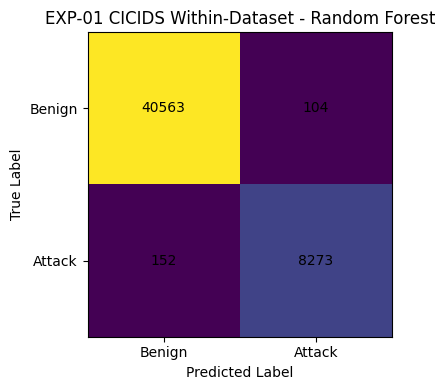


Experiment: EXP-01 CICIDS Within-Dataset
Model: XGBoost
Accuracy: 0.9946
Macro F1: 0.9904
Macro Recall: 0.9912
FPR: 0.0037
Training time: 1.47 seconds
Inference time: 0.1 seconds

Confusion Matrix:
[[40518   149]
 [  118  8307]]

Classification Report:
               precision    recall  f1-score   support

Benign/Normal       1.00      1.00      1.00     40667
       Attack       0.98      0.99      0.98      8425

     accuracy                           0.99     49092
    macro avg       0.99      0.99      0.99     49092
 weighted avg       0.99      0.99      0.99     49092



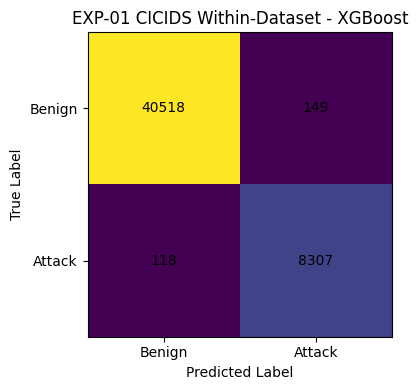


Experiment: EXP-01 CICIDS Within-Dataset
Model: LightGBM
Accuracy: 0.9946
Macro F1: 0.9906
Macro Recall: 0.9916
FPR: 0.0038
Training time: 3.24 seconds
Inference time: 0.18 seconds

Confusion Matrix:
[[40514   153]
 [  110  8315]]

Classification Report:
               precision    recall  f1-score   support

Benign/Normal       1.00      1.00      1.00     40667
       Attack       0.98      0.99      0.98      8425

     accuracy                           0.99     49092
    macro avg       0.99      0.99      0.99     49092
 weighted avg       0.99      0.99      0.99     49092



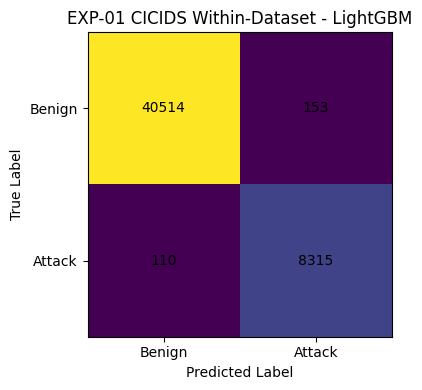


Experiment: EXP-01 CICIDS Within-Dataset
Model: CatBoost
Accuracy: 0.992
Macro F1: 0.986
Macro Recall: 0.9885
FPR: 0.0062
Training time: 3.01 seconds
Inference time: 0.03 seconds

Confusion Matrix:
[[40414   253]
 [  141  8284]]

Classification Report:
               precision    recall  f1-score   support

Benign/Normal       1.00      0.99      1.00     40667
       Attack       0.97      0.98      0.98      8425

     accuracy                           0.99     49092
    macro avg       0.98      0.99      0.99     49092
 weighted avg       0.99      0.99      0.99     49092



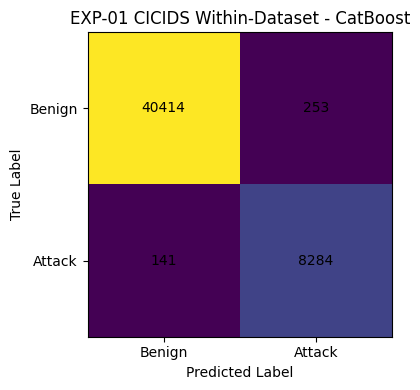

,Experiment,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,FPR,TN,FP,FN,TP,Training_Time_sec,Inference_Time_sec,Test_Samples
0,EXP-01 CICIDS Within-Dataset,Random Forest,0.994785,0.991926,0.989701,0.990809,0.002557,40563,104,152,8273,19.470383,0.258822,49092
1,EXP-01 CICIDS Within-Dataset,XGBoost,0.994561,0.989738,0.991165,0.990450,0.003664,40518,149,118,8307,1.472064,0.104156,49092
2,EXP-01 CICIDS Within-Dataset,LightGBM,0.994643,0.989612,0.991591,0.990598,0.003762,40514,153,110,8315,3.238023,0.179552,49092
3,EXP-01 CICIDS Within-Dataset,CatBoost,0.991974,0.983444,0.988521,0.985960,0.006221,40414,253,141,8284,3.014860,0.028740,49092


In [ ]:
X_cic_train = cic_train[COMMON_FEATURES]
y_cic_train = cic_train["label"]

X_cic_test = cic_test[COMMON_FEATURES]
y_cic_test = cic_test["label"]

exp01_results, exp01_models = evaluate_experiment(
    "EXP-01 CICIDS Within-Dataset",
    X_cic_train,
    y_cic_train,
    X_cic_test,
    y_cic_test
)

display(exp01_results)

### Cell 35 - EXP-02: UNSW-NB15 to UNSW-NB15


Experiment: EXP-02 UNSW Within-Dataset
Model: Random Forest
Accuracy: 0.8755
Macro F1: 0.8712
Macro Recall: 0.8659
FPR: 0.2289
Training time: 16.53 seconds
Inference time: 0.58 seconds

Confusion Matrix:
[[28532  8468]
 [ 1783 43549]]

Classification Report:
               precision    recall  f1-score   support

Benign/Normal       0.94      0.77      0.85     37000
       Attack       0.84      0.96      0.89     45332

     accuracy                           0.88     82332
    macro avg       0.89      0.87      0.87     82332
 weighted avg       0.88      0.88      0.87     82332



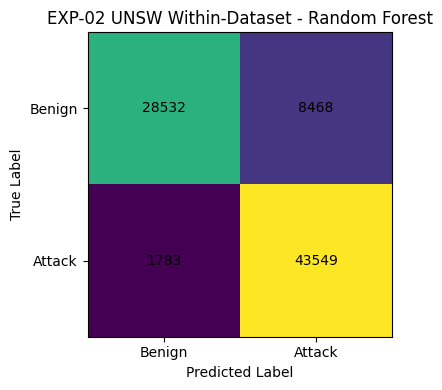


Experiment: EXP-02 UNSW Within-Dataset
Model: XGBoost
Accuracy: 0.9024
Macro F1: 0.9006
Macro Recall: 0.8982
FPR: 0.1436
Training time: 2.84 seconds
Inference time: 0.21 seconds

Confusion Matrix:
[[31687  5313]
 [ 2723 42609]]

Classification Report:
               precision    recall  f1-score   support

Benign/Normal       0.92      0.86      0.89     37000
       Attack       0.89      0.94      0.91     45332

     accuracy                           0.90     82332
    macro avg       0.90      0.90      0.90     82332
 weighted avg       0.90      0.90      0.90     82332



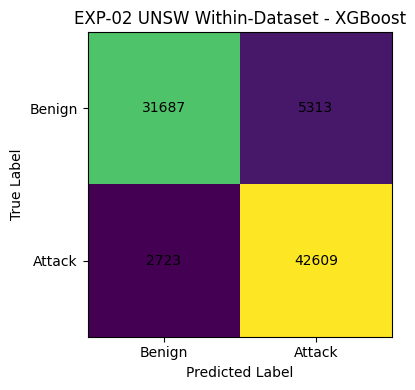


Experiment: EXP-02 UNSW Within-Dataset
Model: LightGBM
Accuracy: 0.9014
Macro F1: 0.8995
Macro Recall: 0.8969
FPR: 0.147
Training time: 1.2 seconds
Inference time: 0.29 seconds

Confusion Matrix:
[[31562  5438]
 [ 2683 42649]]

Classification Report:
               precision    recall  f1-score   support

Benign/Normal       0.92      0.85      0.89     37000
       Attack       0.89      0.94      0.91     45332

     accuracy                           0.90     82332
    macro avg       0.90      0.90      0.90     82332
 weighted avg       0.90      0.90      0.90     82332



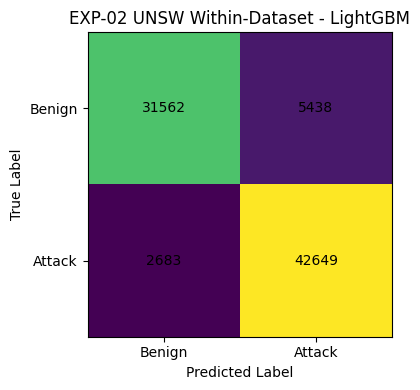


Experiment: EXP-02 UNSW Within-Dataset
Model: CatBoost
Accuracy: 0.8874
Macro F1: 0.8851
Macro Recall: 0.8821
FPR: 0.1704
Training time: 2.66 seconds
Inference time: 0.06 seconds

Confusion Matrix:
[[30694  6306]
 [ 2966 42366]]

Classification Report:
               precision    recall  f1-score   support

Benign/Normal       0.91      0.83      0.87     37000
       Attack       0.87      0.93      0.90     45332

     accuracy                           0.89     82332
    macro avg       0.89      0.88      0.89     82332
 weighted avg       0.89      0.89      0.89     82332



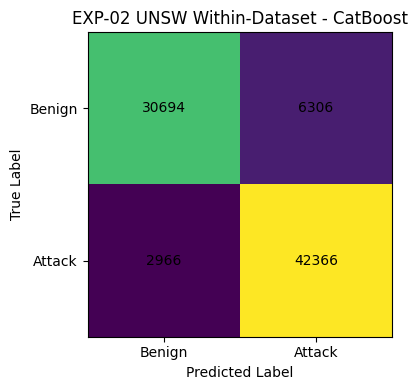

,Experiment,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,FPR,TN,FP,FN,TP,Training_Time_sec,Inference_Time_sec,Test_Samples
0,EXP-02 UNSW Within-Dataset,Random Forest,0.875492,0.889196,0.865902,0.871207,0.228865,28532,8468,1783,43549,16.529076,0.576419,82332
1,EXP-02 UNSW Within-Dataset,XGBoost,0.902395,0.904999,0.898169,0.900647,0.143595,31687,5313,2723,42609,2.843909,0.213523,82332
2,EXP-02 UNSW Within-Dataset,LightGBM,0.901363,0.904283,0.896921,0.899541,0.146973,31562,5438,2683,42649,1.202409,0.289358,82332
3,EXP-02 UNSW Within-Dataset,CatBoost,0.887383,0.891161,0.882070,0.885073,0.170432,30694,6306,2966,42366,2.663043,0.062698,82332


In [ ]:
X_unsw_train = unsw_train_exp[COMMON_FEATURES]
y_unsw_train = unsw_train_exp["label"]

X_unsw_test = unsw_test_exp[COMMON_FEATURES]
y_unsw_test = unsw_test_exp["label"]

exp02_results, exp02_models = evaluate_experiment(
    "EXP-02 UNSW Within-Dataset",
    X_unsw_train,
    y_unsw_train,
    X_unsw_test,
    y_unsw_test
)

display(exp02_results)

### Cell 36 - EXP-03: CICIDS2017 to UNSW-NB15


Experiment: EXP-03 CICIDS to UNSW
Model: Random Forest
Accuracy: 0.4494
Macro F1: 0.3101
Macro Recall: 0.5
FPR: 0.0
Training time: 20.09 seconds
Inference time: 0.25 seconds

Confusion Matrix:
[[37000     0]
 [45332     0]]

Classification Report:
               precision    recall  f1-score   support

Benign/Normal       0.45      1.00      0.62     37000
       Attack       0.00      0.00      0.00     45332

     accuracy                           0.45     82332
    macro avg       0.22      0.50      0.31     82332
 weighted avg       0.20      0.45      0.28     82332



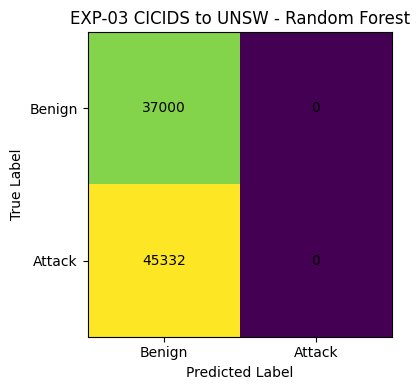


Experiment: EXP-03 CICIDS to UNSW
Model: XGBoost
Accuracy: 0.4473
Macro F1: 0.3095
Macro Recall: 0.4976
FPR: 0.0053
Training time: 1.42 seconds
Inference time: 0.15 seconds

Confusion Matrix:
[[36805   195]
 [45310    22]]

Classification Report:
               precision    recall  f1-score   support

Benign/Normal       0.45      0.99      0.62     37000
       Attack       0.10      0.00      0.00     45332

     accuracy                           0.45     82332
    macro avg       0.27      0.50      0.31     82332
 weighted avg       0.26      0.45      0.28     82332



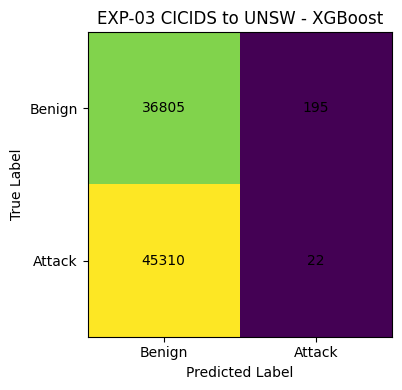


Experiment: EXP-03 CICIDS to UNSW
Model: LightGBM
Accuracy: 0.4495
Macro F1: 0.3113
Macro Recall: 0.5
FPR: 0.0015
Training time: 1.51 seconds
Inference time: 0.26 seconds

Confusion Matrix:
[[36944    56]
 [45267    65]]

Classification Report:
               precision    recall  f1-score   support

Benign/Normal       0.45      1.00      0.62     37000
       Attack       0.54      0.00      0.00     45332

     accuracy                           0.45     82332
    macro avg       0.49      0.50      0.31     82332
 weighted avg       0.50      0.45      0.28     82332



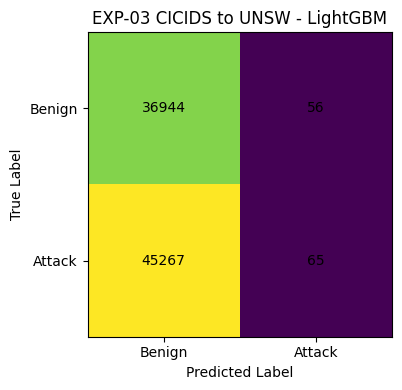


Experiment: EXP-03 CICIDS to UNSW
Model: CatBoost
Accuracy: 0.4463
Macro F1: 0.3113
Macro Recall: 0.4961
FPR: 0.011
Training time: 2.7 seconds
Inference time: 0.04 seconds

Confusion Matrix:
[[36594   406]
 [45184   148]]

Classification Report:
               precision    recall  f1-score   support

Benign/Normal       0.45      0.99      0.62     37000
       Attack       0.27      0.00      0.01     45332

     accuracy                           0.45     82332
    macro avg       0.36      0.50      0.31     82332
 weighted avg       0.35      0.45      0.28     82332



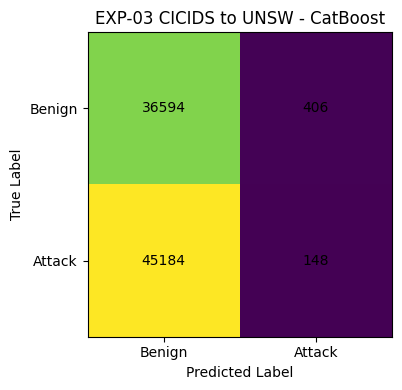

,Experiment,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,FPR,TN,FP,FN,TP,Training_Time_sec,Inference_Time_sec,Test_Samples
0,EXP-03 CICIDS to UNSW,Random Forest,0.449400,0.224700,0.500000,0.310059,0.000000,37000,0,45332,0,20.088142,0.245132,82332
1,EXP-03 CICIDS to UNSW,XGBoost,0.447299,0.274798,0.497608,0.309470,0.005270,36805,195,45310,22,1.416841,0.146025,82332
2,EXP-03 CICIDS to UNSW,LightGBM,0.449509,0.493285,0.499960,0.311334,0.001514,36944,56,45267,65,1.511490,0.260764,82332
3,EXP-03 CICIDS to UNSW,CatBoost,0.446266,0.357314,0.496146,0.311313,0.010973,36594,406,45184,148,2.702386,0.037108,82332


In [ ]:
exp03_results, exp03_models = evaluate_experiment(
    "EXP-03 CICIDS to UNSW",
    X_cic_train,
    y_cic_train,
    X_unsw_test,
    y_unsw_test
)

display(exp03_results)

### Cell 37 - EXP-04: UNSW-NB15 to CICIDS2017


Experiment: EXP-04 UNSW to CICIDS
Model: Random Forest
Accuracy: 0.3879
Macro F1: 0.3646
Macro Recall: 0.461
FPR: 0.6504
Training time: 17.37 seconds
Inference time: 0.41 seconds

Confusion Matrix:
[[14218 26449]
 [ 3602  4823]]

Classification Report:
               precision    recall  f1-score   support

Benign/Normal       0.80      0.35      0.49     40667
       Attack       0.15      0.57      0.24      8425

     accuracy                           0.39     49092
    macro avg       0.48      0.46      0.36     49092
 weighted avg       0.69      0.39      0.44     49092



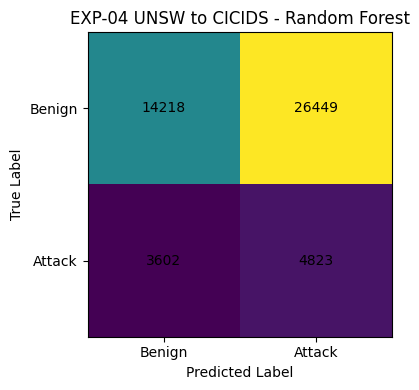


Experiment: EXP-04 UNSW to CICIDS
Model: XGBoost
Accuracy: 0.4398
Macro F1: 0.3699
Macro Recall: 0.3886
FPR: 0.5334
Training time: 1.21 seconds
Inference time: 0.09 seconds

Confusion Matrix:
[[18976 21691]
 [ 5808  2617]]

Classification Report:
               precision    recall  f1-score   support

Benign/Normal       0.77      0.47      0.58     40667
       Attack       0.11      0.31      0.16      8425

     accuracy                           0.44     49092
    macro avg       0.44      0.39      0.37     49092
 weighted avg       0.65      0.44      0.51     49092



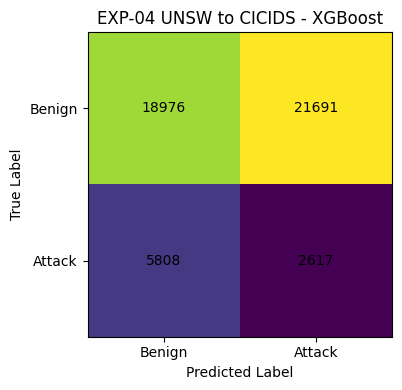


Experiment: EXP-04 UNSW to CICIDS
Model: LightGBM
Accuracy: 0.5319
Macro F1: 0.4327
Macro Recall: 0.4523
FPR: 0.4265
Training time: 1.2 seconds
Inference time: 0.17 seconds

Confusion Matrix:
[[23323 17344]
 [ 5635  2790]]

Classification Report:
               precision    recall  f1-score   support

Benign/Normal       0.81      0.57      0.67     40667
       Attack       0.14      0.33      0.20      8425

     accuracy                           0.53     49092
    macro avg       0.47      0.45      0.43     49092
 weighted avg       0.69      0.53      0.59     49092



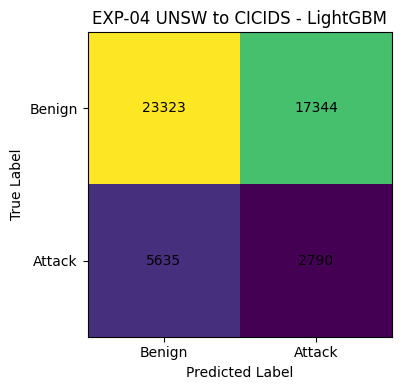


Experiment: EXP-04 UNSW to CICIDS
Model: CatBoost
Accuracy: 0.3315
Macro F1: 0.3278
Macro Recall: 0.4978
FPR: 0.7554
Training time: 2.27 seconds
Inference time: 0.02 seconds

Confusion Matrix:
[[ 9946 30721]
 [ 2098  6327]]

Classification Report:
               precision    recall  f1-score   support

Benign/Normal       0.83      0.24      0.38     40667
       Attack       0.17      0.75      0.28      8425

     accuracy                           0.33     49092
    macro avg       0.50      0.50      0.33     49092
 weighted avg       0.71      0.33      0.36     49092



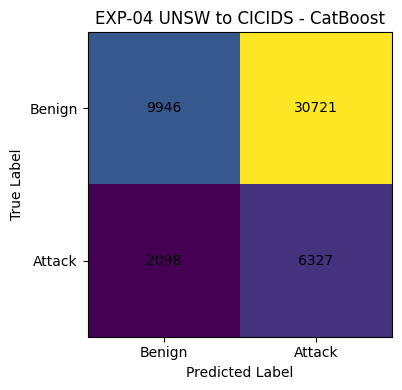

,Experiment,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,FPR,TN,FP,FN,TP,Training_Time_sec,Inference_Time_sec,Test_Samples
0,EXP-04 UNSW to CICIDS,Random Forest,0.387864,0.476047,0.461041,0.364592,0.650380,14218,26449,3602,4823,17.371960,0.408753,49092
1,EXP-04 UNSW to CICIDS,XGBoost,0.439848,0.436658,0.388621,0.369877,0.533381,18976,21691,5808,2617,1.205368,0.090542,49092
2,EXP-04 UNSW to CICIDS,LightGBM,0.531920,0.471990,0.452334,0.432673,0.426488,23323,17344,5635,2790,1.203708,0.168935,49092
3,EXP-04 UNSW to CICIDS,CatBoost,0.331480,0.498292,0.497775,0.327827,0.755428,9946,30721,2098,6327,2.273983,0.023618,49092


In [ ]:
exp04_results, exp04_models = evaluate_experiment(
    "EXP-04 UNSW to CICIDS",
    X_unsw_train,
    y_unsw_train,
    X_cic_test,
    y_cic_test
)

display(exp04_results)

### Cell 38 - Combine all experimental results

In [ ]:
all_results = pd.concat(
    [
        exp01_results,
        exp02_results,
        exp03_results,
        exp04_results
    ],
    ignore_index=True
)

display(
    all_results.sort_values(
        ["Experiment", "Macro_F1"],
        ascending=[True, False]
    )
)

all_results.to_csv(
    OUTPUT_DIR / "project13_all_experiment_results.csv",
    index=False
)

print("Combined experimental results saved.")

,Experiment,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,FPR,TN,FP,FN,TP,Training_Time_sec,Inference_Time_sec,Test_Samples
0,EXP-01 CICIDS Within-Dataset,Random Forest,0.994785,0.991926,0.989701,0.990809,0.002557,40563,104,152,8273,19.470383,0.258822,49092
2,EXP-01 CICIDS Within-Dataset,LightGBM,0.994643,0.989612,0.991591,0.990598,0.003762,40514,153,110,8315,3.238023,0.179552,49092
1,EXP-01 CICIDS Within-Dataset,XGBoost,0.994561,0.989738,0.991165,0.990450,0.003664,40518,149,118,8307,1.472064,0.104156,49092
3,EXP-01 CICIDS Within-Dataset,CatBoost,0.991974,0.983444,0.988521,0.985960,0.006221,40414,253,141,8284,3.014860,0.028740,49092
5,EXP-02 UNSW Within-Dataset,XGBoost,0.902395,0.904999,0.898169,0.900647,0.143595,31687,5313,2723,42609,2.843909,0.213523,82332
6,EXP-02 UNSW Within-Dataset,LightGBM,0.901363,0.904283,0.896921,0.899541,0.146973,31562,5438,2683,42649,1.202409,0.289358,82332
7,EXP-02 UNSW Within-Dataset,CatBoost,0.887383,0.891161,0.882070,0.885073,0.170432,30694,6306,2966,42366,2.663043,0.062698,82332
4,EXP-02 UNSW Within-Dataset,Random Forest,0.875492,0.889196,0.865902,0.871207,0.228865,28532,8468,1783,43549,16.529076,0.576419,82332
10,EXP-03 CICIDS to UNSW,LightGBM,0.449509,0.493285,0.499960,0.311334,0.001514,36944,56,45267,65,1.511490,0.260764,82332
11,EXP-03 CICIDS to UNSW,CatBoost,0.446266,0.357314,0.496146,0.311313,0.010973,36594,406,45184,148,2.702386,0.037108,82332


Combined experimental results saved.


### Cell 39 - Compare macro-F1 across experiments

Experiment,EXP-01 CICIDS Within-Dataset,EXP-02 UNSW Within-Dataset,EXP-03 CICIDS to UNSW,EXP-04 UNSW to CICIDS
Model,,,,
CatBoost,0.985960,0.885073,0.311313,0.327827
LightGBM,0.990598,0.899541,0.311334,0.432673
Random Forest,0.990809,0.871207,0.310059,0.364592
XGBoost,0.990450,0.900647,0.309470,0.369877


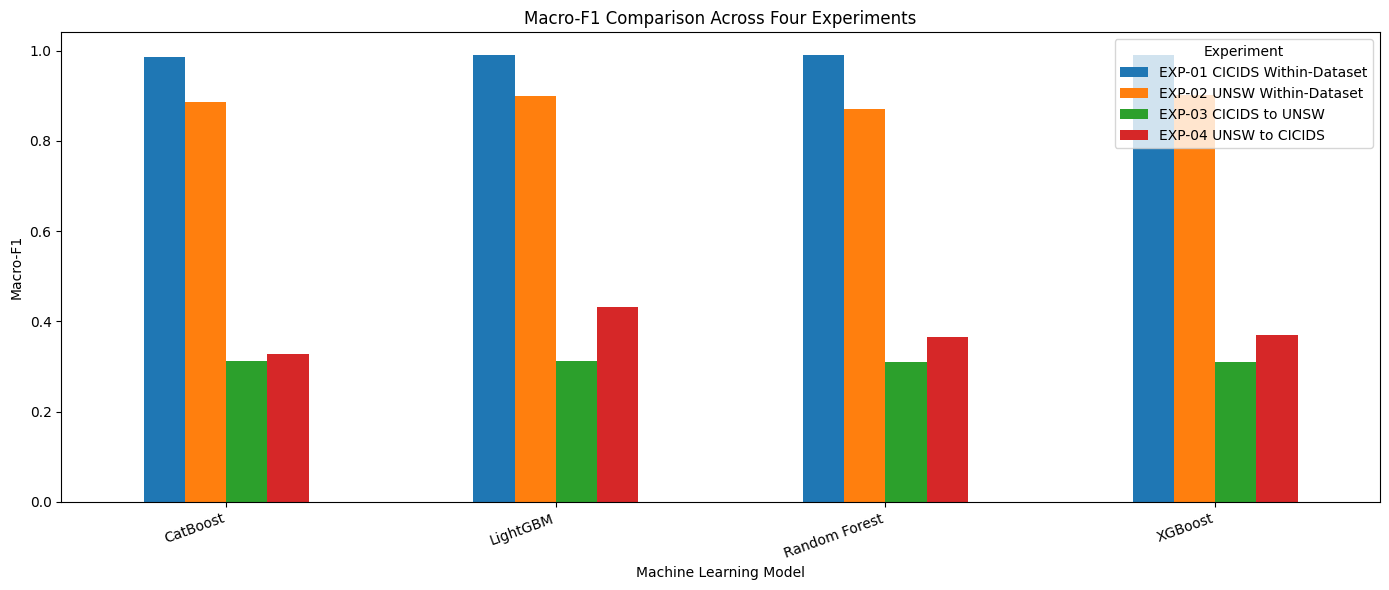

In [ ]:
pivot_f1 = all_results.pivot(
    index="Model",
    columns="Experiment",
    values="Macro_F1"
)

display(pivot_f1)

ax = pivot_f1.plot(
    kind="bar",
    figsize=(14, 6)
)

ax.set_title("Macro-F1 Comparison Across Four Experiments")
ax.set_ylabel("Macro-F1")
ax.set_xlabel("Machine Learning Model")

plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "project13_macro_f1_comparison.png",
    dpi=150
)

plt.show()

### Cell 40 - Compare accuracy

Experiment,EXP-01 CICIDS Within-Dataset,EXP-02 UNSW Within-Dataset,EXP-03 CICIDS to UNSW,EXP-04 UNSW to CICIDS
Model,,,,
CatBoost,0.991974,0.887383,0.446266,0.331480
LightGBM,0.994643,0.901363,0.449509,0.531920
Random Forest,0.994785,0.875492,0.449400,0.387864
XGBoost,0.994561,0.902395,0.447299,0.439848


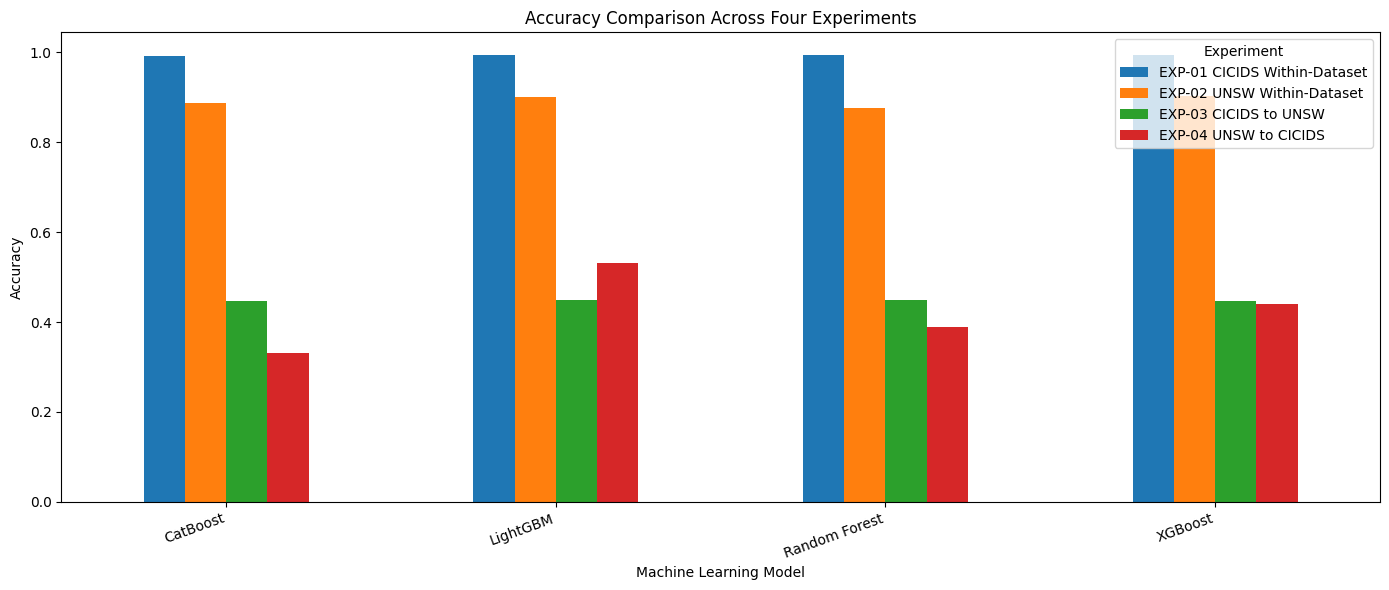

In [ ]:
pivot_accuracy = all_results.pivot(
    index="Model",
    columns="Experiment",
    values="Accuracy"
)

display(pivot_accuracy)

ax = pivot_accuracy.plot(
    kind="bar",
    figsize=(14, 6)
)

ax.set_title("Accuracy Comparison Across Four Experiments")
ax.set_ylabel("Accuracy")
ax.set_xlabel("Machine Learning Model")

plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "project13_accuracy_comparison.png",
    dpi=150
)

plt.show()

### Cell 41 - Compare false positive rates

Experiment,EXP-01 CICIDS Within-Dataset,EXP-02 UNSW Within-Dataset,EXP-03 CICIDS to UNSW,EXP-04 UNSW to CICIDS
Model,,,,
CatBoost,0.006221,0.170432,0.010973,0.755428
LightGBM,0.003762,0.146973,0.001514,0.426488
Random Forest,0.002557,0.228865,0.000000,0.650380
XGBoost,0.003664,0.143595,0.005270,0.533381


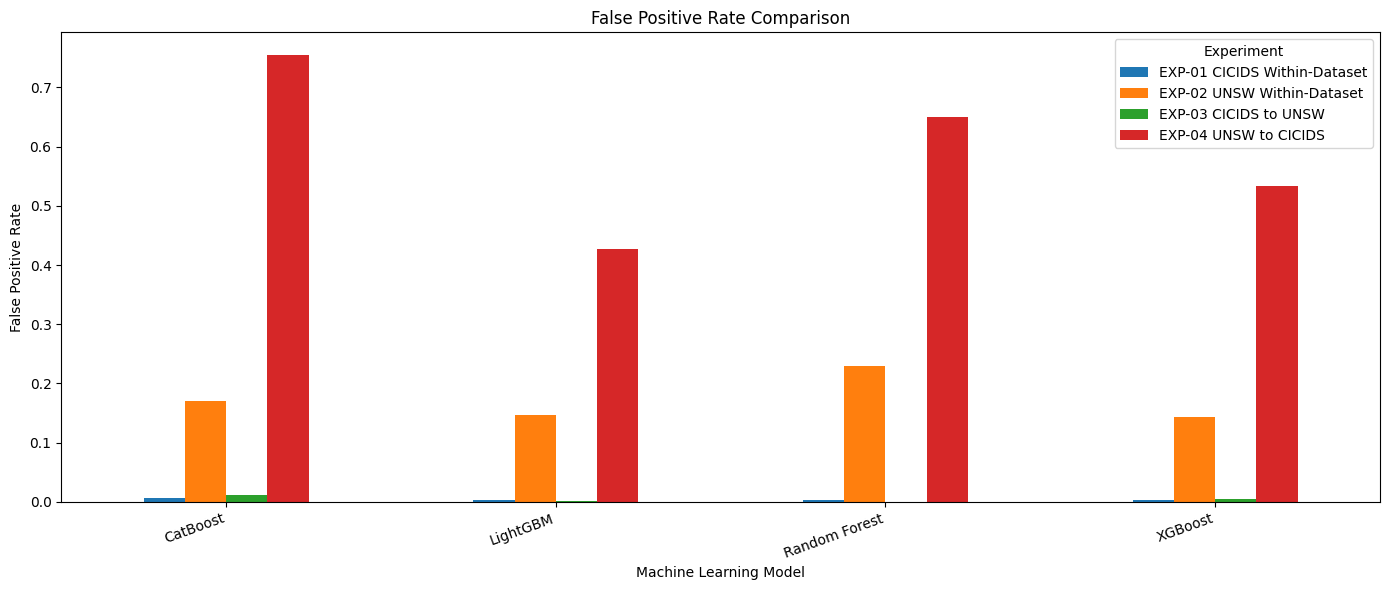

In [ ]:
pivot_fpr = all_results.pivot(
    index="Model",
    columns="Experiment",
    values="FPR"
)

display(pivot_fpr)

ax = pivot_fpr.plot(
    kind="bar",
    figsize=(14, 6)
)

ax.set_title("False Positive Rate Comparison")
ax.set_ylabel("False Positive Rate")
ax.set_xlabel("Machine Learning Model")

plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "project13_fpr_comparison.png",
    dpi=150
)

plt.show()

### Cell 42 — Identify the best model in each experiment

In [ ]:
best_models = (
    all_results
    .sort_values("Macro_F1", ascending=False)
    .groupby("Experiment")
    .head(1)
    .reset_index(drop=True)
)

display(
    best_models[
        [
            "Experiment",
            "Model",
            "Accuracy",
            "Macro_Precision",
            "Macro_Recall",
            "Macro_F1",
            "FPR"
        ]
    ]
)

best_models.to_csv(
    OUTPUT_DIR / "project13_best_models.csv",
    index=False
)

,Experiment,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,FPR
0,EXP-01 CICIDS Within-Dataset,Random Forest,0.994785,0.991926,0.989701,0.990809,0.002557
1,EXP-02 UNSW Within-Dataset,XGBoost,0.902395,0.904999,0.898169,0.900647,0.143595
2,EXP-04 UNSW to CICIDS,LightGBM,0.531920,0.471990,0.452334,0.432673,0.426488
3,EXP-03 CICIDS to UNSW,LightGBM,0.449509,0.493285,0.499960,0.311334,0.001514


### Cell 43 - Calculate cross-dataset generalization gaps

In [ ]:
generalization_rows = []

for model_name in all_results["Model"].unique():

    model_results = all_results[
        all_results["Model"] == model_name
    ].set_index("Experiment")

    cic_within = model_results.loc[
        "EXP-01 CICIDS Within-Dataset",
        "Macro_F1"
    ]

    unsw_within = model_results.loc[
        "EXP-02 UNSW Within-Dataset",
        "Macro_F1"
    ]

    cic_to_unsw = model_results.loc[
        "EXP-03 CICIDS to UNSW",
        "Macro_F1"
    ]

    unsw_to_cic = model_results.loc[
        "EXP-04 UNSW to CICIDS",
        "Macro_F1"
    ]

    generalization_rows.append({
        "Model": model_name,
        "CICIDS_Within_F1": cic_within,
        "CICIDS_to_UNSW_F1": cic_to_unsw,
        "CICIDS_to_UNSW_Gap": cic_within - cic_to_unsw,
        "UNSW_Within_F1": unsw_within,
        "UNSW_to_CICIDS_F1": unsw_to_cic,
        "UNSW_to_CICIDS_Gap": unsw_within - unsw_to_cic
    })

generalization_df = pd.DataFrame(generalization_rows)

display(generalization_df)

generalization_df.to_csv(
    OUTPUT_DIR / "project13_generalization_gap.csv",
    index=False
)

,Model,CICIDS_Within_F1,CICIDS_to_UNSW_F1,CICIDS_to_UNSW_Gap,UNSW_Within_F1,UNSW_to_CICIDS_F1,UNSW_to_CICIDS_Gap
0,Random Forest,0.990809,0.310059,0.680750,0.871207,0.364592,0.506615
1,XGBoost,0.990450,0.309470,0.680980,0.900647,0.369877,0.530770
2,LightGBM,0.990598,0.311334,0.679264,0.899541,0.432673,0.466868
3,CatBoost,0.985960,0.311313,0.674648,0.885073,0.327827,0.557246


### Cell 44 - Generate final experiment summary

In [ ]:
import json

best_models = (
    all_results
    .sort_values("Macro_F1", ascending=False)
    .groupby("Experiment")
    .head(1)
    .reset_index(drop=True)
)

summary = {
    "project": "Cross-Dataset IDS Evaluation",
    "datasets": [
        "CICIDS2017",
        "UNSW-NB15"
    ],
    "common_features": COMMON_FEATURES,
    "experiments": [
        "EXP-01 CICIDS Within-Dataset",
        "EXP-02 UNSW Within-Dataset",
        "EXP-03 CICIDS to UNSW",
        "EXP-04 UNSW to CICIDS"
    ],
    "models": all_results["Model"].unique().tolist(),
    "results": all_results.to_dict(orient="records"),
    "best_models": best_models.to_dict(orient="records"),
    "generalization_gaps": generalization_df.to_dict(orient="records")
}

with open(
    OUTPUT_DIR / "project13_final_summary.json",
    "w"
) as f:
    json.dump(summary, f, indent=4, default=str)

print("Final summary generated.")
print("Output folder:", OUTPUT_DIR)

Final summary generated.
Output folder: /content/drive/MyDrive/Colab Notebooks/Projects House/project-13/Output-4


### Cell 45 - List all generated outputs

In [ ]:
print("PROJECT 13 OUTPUT FILES")
print("=" * 60)

for file in sorted(OUTPUT_DIR.glob("*")):
    print(file.name)

PROJECT 13 OUTPUT FILES
cicids_test_prepared.csv
cicids_train_prepared.csv
dataset_audit.json
exp-01_cicids_within-dataset_catboost.joblib
exp-01_cicids_within-dataset_catboost_confusion_matrix.png
exp-01_cicids_within-dataset_catboost_report.csv
exp-01_cicids_within-dataset_lightgbm.joblib
exp-01_cicids_within-dataset_lightgbm_confusion_matrix.png
exp-01_cicids_within-dataset_lightgbm_report.csv
exp-01_cicids_within-dataset_random_forest.joblib
exp-01_cicids_within-dataset_random_forest_confusion_matrix.png
exp-01_cicids_within-dataset_random_forest_report.csv
exp-01_cicids_within-dataset_xgboost.joblib
exp-01_cicids_within-dataset_xgboost_confusion_matrix.png
exp-01_cicids_within-dataset_xgboost_report.csv
exp-02_unsw_within-dataset_catboost.joblib
exp-02_unsw_within-dataset_catboost_confusion_matrix.png
exp-02_unsw_within-dataset_catboost_report.csv
exp-02_unsw_within-dataset_lightgbm.joblib
exp-02_unsw_within-dataset_lightgbm_confusion_matrix.png
exp-02_unsw_within-dataset_lightgbm

## Additional Validation — Sampling, Domain Separability, and Multi-Seed Robustness

These validation cells extend the existing leakage-audited four-experiment workflow. Run the notebook from the beginning before executing these cells. The original four experiment results are retained; the additional cells write separate validation outputs.

### Cell 46 — CICIDS2017 Sampling and Rare Attack-Category Coverage

Compares the full cleaned CICIDS2017 attack-category distribution with the 250,000-row working sample used by the group-aware split.

In [ ]:
# Cell 46 - CICIDS2017 sampling and rare attack-category coverage

if "attack_category" not in cic_data.columns:
    raise RuntimeError(
        "attack_category is missing. Confirm the Cell 25 update and rerun the notebook from the beginning."
    )

# The original experiment uses cic_working_sample before the group-aware split.
full_category_counts = (
    cic_data["attack_category"]
    .value_counts(dropna=False)
    .rename_axis("Attack_Category")
    .reset_index(name="Full_Cleaned_Count")
)

sample_category_counts = (
    cic_working_sample["attack_category"]
    .value_counts(dropna=False)
    .rename_axis("Attack_Category")
    .reset_index(name="Working_Sample_Count")
)

sampling_comparison = full_category_counts.merge(
    sample_category_counts, on="Attack_Category", how="left"
)
sampling_comparison["Working_Sample_Count"] = (
    sampling_comparison["Working_Sample_Count"].fillna(0).astype(int)
)
sampling_comparison["Full_Cleaned_Percentage"] = (
    sampling_comparison["Full_Cleaned_Count"] / len(cic_data) * 100
)
sampling_comparison["Working_Sample_Percentage"] = (
    sampling_comparison["Working_Sample_Count"] / len(cic_working_sample) * 100
)
sampling_comparison["Retention_Percentage"] = (
    sampling_comparison["Working_Sample_Count"] /
    sampling_comparison["Full_Cleaned_Count"] * 100
)

sampling_comparison = sampling_comparison.sort_values(
    "Full_Cleaned_Count", ascending=True
).reset_index(drop=True)

display(sampling_comparison)

missing_categories = sampling_comparison.loc[
    sampling_comparison["Working_Sample_Count"] == 0, "Attack_Category"
].tolist()

print("Full cleaned CICIDS2017 rows:", len(cic_data))
print("CICIDS2017 working-sample rows:", len(cic_working_sample))
print("Number of attack categories in full data:", len(full_category_counts))
print("Categories absent from working sample:", len(missing_categories))
print("Absent categories:", missing_categories)

sampling_comparison.to_csv(
    OUTPUT_DIR / "cicids_sampling_category_validation.csv", index=False
)


,Attack_Category,Full_Cleaned_Count,Working_Sample_Count,Full_Cleaned_Percentage,Working_Sample_Percentage,Retention_Percentage
0,Heartbleed,11,0,0.000436,0.0000,0.000000
1,Web Attack � Sql Injection,21,2,0.000833,0.0008,9.523810
2,Infiltration,36,3,0.001427,0.0012,8.333333
3,Web Attack � XSS,652,74,0.025850,0.0296,11.349693
4,Web Attack � Brute Force,1470,147,0.058281,0.0588,10.000000
5,Bot,1953,201,0.077431,0.0804,10.291859
6,SSH-Patator,3219,304,0.127624,0.1216,9.443927
7,DoS Slowhttptest,5228,517,0.207275,0.2068,9.889059
8,DoS slowloris,5385,540,0.213499,0.2160,10.027855
9,FTP-Patator,5933,618,0.235226,0.2472,10.416316


Full cleaned CICIDS2017 rows: 2522255
CICIDS2017 working-sample rows: 250000
Number of attack categories in full data: 15
Categories absent from working sample: 1
Absent categories: ['Heartbleed']


### Cell 47 — Dataset-Origin Separability Analysis

Trains a binary classifier to distinguish CICIDS2017 from UNSW-NB15 using the five harmonized features. Exact duplicate feature signatures are grouped so identical signatures do not cross the train/test boundary. ROC-AUC measures dataset-origin separability; it is not, by itself, proof of a specific distribution-shift mechanism.

In [ ]:
# Cell 47 - Dataset-origin separability analysis

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix, classification_report
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from lightgbm import LGBMClassifier

# Use a balanced sample from the cleaned CICIDS2017 data and UNSW training data.
DOMAIN_SAMPLE_SIZE = min(175_000, len(cic_data), len(unsw_train_data))
if DOMAIN_SAMPLE_SIZE < 2:
    raise RuntimeError("Not enough rows for dataset-origin analysis.")

cic_domain = cic_data[COMMON_FEATURES].sample(
    n=DOMAIN_SAMPLE_SIZE, random_state=42
).copy()
unsw_domain = unsw_train_data[COMMON_FEATURES].sample(
    n=DOMAIN_SAMPLE_SIZE, random_state=42
).copy()

cic_domain["dataset_origin"] = 0
unsw_domain["dataset_origin"] = 1
domain_data = pd.concat([cic_domain, unsw_domain], ignore_index=True)
X_domain = domain_data[COMMON_FEATURES].copy()
y_domain = domain_data["dataset_origin"].astype(int)

# Factorize exact feature tuples rather than relying on a hash value.
domain_groups = pd.factorize(pd.MultiIndex.from_frame(X_domain))[0]

domain_splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.30, random_state=42
)
domain_train_idx, domain_test_idx = next(
    domain_splitter.split(X_domain, y_domain, groups=domain_groups)
)

X_domain_train = X_domain.iloc[domain_train_idx]
X_domain_test = X_domain.iloc[domain_test_idx]
y_domain_train = y_domain.iloc[domain_train_idx]
y_domain_test = y_domain.iloc[domain_test_idx]

domain_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("classifier", LGBMClassifier(
        n_estimators=150, learning_rate=0.1,
        random_state=42, n_jobs=-1, verbosity=-1
    ))
])

domain_model.fit(X_domain_train, y_domain_train)
domain_probabilities = domain_model.predict_proba(X_domain_test)[:, 1]
domain_predictions = (domain_probabilities >= 0.5).astype(int)

domain_auc = roc_auc_score(y_domain_test, domain_probabilities)
domain_accuracy = accuracy_score(y_domain_test, domain_predictions)
domain_cm = confusion_matrix(y_domain_test, domain_predictions, labels=[0, 1])

print("Balanced sample per dataset:", DOMAIN_SAMPLE_SIZE)
print("Domain-origin training rows:", len(domain_train_idx))
print("Domain-origin testing rows:", len(domain_test_idx))
print("Test-set origin counts (0=CICIDS2017, 1=UNSW-NB15):")
print(y_domain_test.value_counts().sort_index())
print("Domain-origin ROC-AUC:", round(domain_auc, 6))
print("Domain-origin accuracy:", round(domain_accuracy, 6))
print("Confusion matrix [CICIDS2017, UNSW-NB15]:\n", domain_cm)
print(classification_report(
    y_domain_test, domain_predictions,
    labels=[0, 1], target_names=["CICIDS2017", "UNSW-NB15"],
    zero_division=0
))

domain_origin_summary = pd.DataFrame([{
    "Balanced_Sample_Per_Dataset": DOMAIN_SAMPLE_SIZE,
    "Train_Rows": len(domain_train_idx),
    "Test_Rows": len(domain_test_idx),
    "ROC_AUC": domain_auc,
    "Accuracy": domain_accuracy,
    "TN": int(domain_cm[0, 0]), "FP": int(domain_cm[0, 1]),
    "FN": int(domain_cm[1, 0]), "TP": int(domain_cm[1, 1])
}])
domain_origin_summary.to_csv(
    OUTPUT_DIR / "domain_origin_separability_summary.csv", index=False
)


Balanced sample per dataset: 175000
Domain-origin training rows: 244482
Domain-origin testing rows: 105518
Test-set origin counts (0=CICIDS2017, 1=UNSW-NB15):
dataset_origin
0    52042
1    53476
Name: count, dtype: int64
Domain-origin ROC-AUC: 0.999926
Domain-origin accuracy: 0.997356
Confusion matrix [CICIDS2017, UNSW-NB15]:
 [[51899   143]
 [  136 53340]]
              precision    recall  f1-score   support

  CICIDS2017       1.00      1.00      1.00     52042
   UNSW-NB15       1.00      1.00      1.00     53476

    accuracy                           1.00    105518
   macro avg       1.00      1.00      1.00    105518
weighted avg       1.00      1.00      1.00    105518



### Cell 48 — Multi-Seed Robustness Evaluation

Repeats the four experiments across five seeds. For CICIDS2017, each seed recreates the 250,000-row stratified working sample and exact-signature group split. The official UNSW train/test partitions remain fixed. This is a seed-sensitivity analysis, not an independent resampling of the UNSW official split. The cell fits 80 models and may take substantial time.

In [ ]:
# Cell 48 - Multi-seed robustness evaluation

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

ROBUSTNESS_SEEDS = [42, 7, 21, 100, 2026]
robustness_records = []

# Preserve the original global seed after this validation.
_original_random_state = RANDOM_STATE

try:
    for seed in ROBUSTNESS_SEEDS:
        print(f"\nRunning four experiments for seed={seed}")
        RANDOM_STATE = seed

        # Recreate the stratified CICIDS2017 working sample.
        seed_working_sample, _ = train_test_split(
            cic_data, train_size=250_000,
            stratify=cic_data["label"], random_state=seed
        )

        # Keep identical five-feature signatures in one partition.
        seed_groups = pd.factorize(
            pd.MultiIndex.from_frame(seed_working_sample[COMMON_FEATURES])
        )[0]
        seed_splitter = GroupShuffleSplit(
            n_splits=1, test_size=0.20, random_state=seed
        )
        seed_train_idx, seed_test_idx = next(
            seed_splitter.split(
                seed_working_sample, seed_working_sample["label"],
                groups=seed_groups
            )
        )
        seed_cic_train = seed_working_sample.iloc[seed_train_idx].reset_index(drop=True)
        seed_cic_test = seed_working_sample.iloc[seed_test_idx].reset_index(drop=True)

        # Confirm exact five-feature signatures do not overlap.
        seed_train_signatures = set(
            pd.MultiIndex.from_frame(seed_cic_train[COMMON_FEATURES])
        )
        seed_test_signatures = set(
            pd.MultiIndex.from_frame(seed_cic_test[COMMON_FEATURES])
        )
        if seed_train_signatures.intersection(seed_test_signatures):
            raise RuntimeError(f"Signature overlap detected for seed {seed}.")

        experiment_inputs = [
            ("EXP-01 CICIDS Within-Dataset",
             seed_cic_train[COMMON_FEATURES], seed_cic_train["label"],
             seed_cic_test[COMMON_FEATURES], seed_cic_test["label"]),
            ("EXP-02 UNSW Within-Dataset",
             unsw_train_exp[COMMON_FEATURES], unsw_train_exp["label"],
             unsw_test_exp[COMMON_FEATURES], unsw_test_exp["label"]),
            ("EXP-03 CICIDS to UNSW",
             seed_cic_train[COMMON_FEATURES], seed_cic_train["label"],
             unsw_test_exp[COMMON_FEATURES], unsw_test_exp["label"]),
            ("EXP-04 UNSW to CICIDS",
             unsw_train_exp[COMMON_FEATURES], unsw_train_exp["label"],
             seed_cic_test[COMMON_FEATURES], seed_cic_test["label"])
        ]

        for experiment_name, X_train_seed, y_train_seed, X_test_seed, y_test_seed in experiment_inputs:
            models_seed = create_models(y_train_seed)
            for model_name, model_seed in models_seed.items():
                pipeline_seed = create_pipeline(model_seed)
                start_time = time.time()
                pipeline_seed.fit(X_train_seed, y_train_seed)
                training_seconds = time.time() - start_time

                predictions_seed = pipeline_seed.predict(X_test_seed)
                cm_seed = confusion_matrix(
                    y_test_seed, predictions_seed, labels=[0, 1]
                )
                tn, fp, fn, tp = cm_seed.ravel()
                fpr_seed = fp / (fp + tn) if (fp + tn) else 0.0

                robustness_records.append({
                    "Seed": seed,
                    "Experiment": experiment_name,
                    "Model": model_name,
                    "Accuracy": accuracy_score(y_test_seed, predictions_seed),
                    "Macro_Precision": precision_score(
                        y_test_seed, predictions_seed, average="macro", zero_division=0
                    ),
                    "Macro_Recall": recall_score(
                        y_test_seed, predictions_seed, average="macro", zero_division=0
                    ),
                    "Macro_F1": f1_score(
                        y_test_seed, predictions_seed, average="macro", zero_division=0
                    ),
                    "FPR": fpr_seed,
                    "TN": int(tn), "FP": int(fp),
                    "FN": int(fn), "TP": int(tp),
                    "Training_Time_sec": training_seconds,
                    "Test_Samples": int(len(y_test_seed))
                })
                print(f"  {experiment_name} | {model_name} | Macro-F1={robustness_records[-1]['Macro_F1']:.4f}")
finally:
    RANDOM_STATE = _original_random_state

robustness_df = pd.DataFrame(robustness_records)
robustness_metrics = [
    "Accuracy", "Macro_Precision", "Macro_Recall", "Macro_F1", "FPR"
]
robustness_summary = (
    robustness_df.groupby(["Experiment", "Model"])[robustness_metrics]
    .agg(["mean", "std"])
)
robustness_summary.columns = [
    f"{metric}_{stat}" for metric, stat in robustness_summary.columns
]
robustness_summary = robustness_summary.reset_index()

display(robustness_summary.round(6))

robustness_df.to_csv(
    OUTPUT_DIR / "multi_seed_robustness_results.csv", index=False
)
robustness_summary.to_csv(
    OUTPUT_DIR / "multi_seed_robustness_summary.csv", index=False
)
print("Multi-seed result rows:", len(robustness_df))
print("Original RANDOM_STATE restored to:", RANDOM_STATE)



Running four experiments for seed=42
  EXP-01 CICIDS Within-Dataset | Random Forest | Macro-F1=0.9914
  EXP-01 CICIDS Within-Dataset | XGBoost | Macro-F1=0.9910
  EXP-01 CICIDS Within-Dataset | LightGBM | Macro-F1=0.9910
  EXP-01 CICIDS Within-Dataset | CatBoost | Macro-F1=0.9841
  EXP-02 UNSW Within-Dataset | Random Forest | Macro-F1=0.8712
  EXP-02 UNSW Within-Dataset | XGBoost | Macro-F1=0.9006
  EXP-02 UNSW Within-Dataset | LightGBM | Macro-F1=0.8995
  EXP-02 UNSW Within-Dataset | CatBoost | Macro-F1=0.8851
  EXP-03 CICIDS to UNSW | Random Forest | Macro-F1=0.3101
  EXP-03 CICIDS to UNSW | XGBoost | Macro-F1=0.3103
  EXP-03 CICIDS to UNSW | LightGBM | Macro-F1=0.3107
  EXP-03 CICIDS to UNSW | CatBoost | Macro-F1=0.3113
  EXP-04 UNSW to CICIDS | Random Forest | Macro-F1=0.3709
  EXP-04 UNSW to CICIDS | XGBoost | Macro-F1=0.3752
  EXP-04 UNSW to CICIDS | LightGBM | Macro-F1=0.4344
  EXP-04 UNSW to CICIDS | CatBoost | Macro-F1=0.3308

Running four experiments for seed=7
  EXP-01 CICI

,Experiment,Model,Accuracy_mean,Accuracy_std,Macro_Precision_mean,Macro_Precision_std,Macro_Recall_mean,Macro_Recall_std,Macro_F1_mean,Macro_F1_std,FPR_mean,FPR_std
0,EXP-01 CICIDS Within-Dataset,CatBoost,0.991604,0.000498,0.981742,0.001132,0.988660,0.000690,0.985159,0.000767,0.006898,0.000594
1,EXP-01 CICIDS Within-Dataset,LightGBM,0.994437,0.000442,0.988219,0.001554,0.992058,0.000455,0.990125,0.000895,0.004347,0.000601
2,EXP-01 CICIDS Within-Dataset,Random Forest,0.994914,0.000255,0.991033,0.000504,0.990840,0.000671,0.990936,0.000546,0.003011,0.000155
3,EXP-01 CICIDS Within-Dataset,XGBoost,0.994624,0.000453,0.988802,0.001407,0.992123,0.000658,0.990452,0.000904,0.004100,0.000535
4,EXP-02 UNSW Within-Dataset,CatBoost,0.887334,0.002079,0.891425,0.001486,0.881862,0.002460,0.884968,0.002241,0.172211,0.006351
5,EXP-02 UNSW Within-Dataset,LightGBM,0.901363,0.000000,0.904283,0.000000,0.896921,0.000000,0.899541,0.000000,0.146973,0.000000
6,EXP-02 UNSW Within-Dataset,Random Forest,0.875854,0.000381,0.889543,0.000321,0.866280,0.000413,0.871588,0.000407,0.228324,0.000733
7,EXP-02 UNSW Within-Dataset,XGBoost,0.901720,0.000612,0.904329,0.000524,0.897473,0.000695,0.899955,0.000642,0.144497,0.001694
8,EXP-03 CICIDS to UNSW,CatBoost,0.445963,0.001047,0.346242,0.029447,0.495829,0.001189,0.311004,0.001104,0.011416,0.002917
9,EXP-03 CICIDS to UNSW,LightGBM,0.449106,0.000616,0.474833,0.156427,0.499539,0.000661,0.310931,0.000707,0.002108,0.001288


Multi-seed result rows: 80
Original RANDOM_STATE restored to: 42
